# Data11 frequency range analysis

The published configuration selects one sweep recording per enabled material/structure and one independently acquired accelerometer reference. Run the cells in order to inspect raw waveforms, review the selected records, and calculate harmonic-tracking results. Original data are read-only; each analysis creates a new run.

| Quantity | Definition for the published selection |
|---|---|
| Frequency trajectory | Broad-band STFT ridge initialization followed by a data-fitted logarithmic sweep |
| IM amplitude | Selected recording's fundamental peak counts, using complex demodulation with a centered Hann kernel |
| Responsivity | Selected IM peak counts / independently recorded accelerometer peak g at common accepted frequencies |
| SNR | Fundamental amplitude / background amplitude from the same tracking estimator |
| Detectable interval | Adjacent valid grid points with an accepted sweep and amplifier-on SNR strictly above 10 dB |

A single recording provides no between-recording SD or repeatability estimate. This offline implementation does not claim to reproduce proprietary Siemens software. Figures use 17 pt text and the available release font; numerical CSVs retain both noise conditions and separate SNR definitions.

Historical previews, reference timestamp-gap views and the separate whole-sweep FFT comparison are in [the optional supplement](data11_frequency_range_supplement.ipynb).


## 1. Data and frequency selection

Edit `RAW_FREQUENCIES_HZ`, `RAW_FILE` and `CONFIG['materials']` below. Each material maps to `[noise IDs, sweep IDs]`; noise order is nothing-on, amplifier-on. The published selection uses one sweep per enabled material/structure; an empty sweep list excludes a material. The two noise recordings are separate background conditions, not additional signal repeats.

The recorded selection ranked accepted tracking points, then logarithmic-trajectory residuals, without selecting larger SNR or amplitude. Material 12 remains excluded because IM_30/31/32 have numerical endpoint anomalies. IM_58/60/62/63/64 remain deferred and are not analyzed by the current selection. Historical selection evidence is available in the supplement.


In [1]:
# Frequency and input selection: run this cell after editing
from pathlib import Path
from copy import deepcopy
import sys, importlib
import pandas as pd
from IPython.display import display, Image
for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "release_manifest.json").is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break
from portable_runtime import project_root, data_root, ensure_environment, notebook_path
PROJECT = project_root()
ensure_environment()
NOTEBOOK_PATH = notebook_path("data11_frequency_range_analysis")
import data11_config
import data11_harmonic_tracking as ht
importlib.reload(data11_config)
importlib.reload(ht)
CONFIG = ht.tracking_config()
CONFIG["data_root"] = str(data_root("Data11"))

# A. Raw waveforms: three frequencies from one thin OO-50 recording.
RAW_FREQUENCIES_HZ = [50., 100., 150.]  # Requested center frequencies
RAW_FILE = 'IM_4.csv'                 # Selected thin OO-50 recording
RAW_WINDOW_MS = 200.
RAW_DISPLAY = 'raw'  # 'raw' retains DC; 'detrended' removes a linear trend

# B. Material mapping: [[nothing-on noise, amplifier-on noise], [sweep IDs]].
# Published selection: one sweep per enabled material; retain both noise conditions.
# Quality-reviewed selection; [] means no selected sweep.
CONFIG['materials'] = {
    'OO-50 0.23 mm': [[1, 2], [4]],
    '10 NV': [[18, 19], [20]],
    '945': [[23, 24], [27]],
    '18': [[33, 34], [36]],
    'OO-50 4.05 mm': [[38, 39], [42]],
    'Foam 4.17 mm': [[43, 44], [46]],
    'OO-50 large coil, silicone bonded, 3.5 uH': [[49, 50], [52]],
}
# Deferred supplementary recordings are listed for exclusion, not read.
CONFIG['deferred_sweep_ids'] = [58, 60, 62, 63, 64]
conflicts = sorted({i for _, ids in CONFIG['materials'].values() for i in ids}
                   & set(CONFIG['deferred_sweep_ids']))
if conflicts:
    raise ValueError(f'Deferred records are selected: {conflicts}. Remove them from sweep IDs.')

# Independently acquired accelerometer reference; no file pairing.
CONFIG['accel_sweeps'] = [3]  # Independent reference recording(s)
CONFIG['accel_noise'] = [1, 2]
CONFIG['window_s'] = 0.8
CONFIG['grid_points'] = 81
CONFIG['snr_threshold_db'] = 10.
CONFIG['minimum_repeat_count'] = 1  # One accepted sweep per sensor is allowed
CONFIG['figure_font_size_pt'] = 17  # Text size for exported PNG/SVG
CONFIG['noise_start_s'] = 5.
CONFIG['max_noise_windows'] = 30
CONFIG['nominal_start_overrides_s'] = {}
print('Raw waveform:', RAW_FILE, RAW_FREQUENCIES_HZ, 'Hz;', RAW_WINDOW_MS, 'ms')
display(pd.DataFrame([{'material': k, 'noise_ids': v[0], 'sweep_ids': v[1]}
                      for k, v in CONFIG['materials'].items()]))


Raw waveform: IM_4.csv [50.0, 100.0, 150.0] Hz; 200.0 ms


,material,noise_ids,sweep_ids
0,OO-50 0.23 mm,"[1, 2]",[4]
1,10 NV,"[18, 19]",[20]
2,945,"[23, 24]",[27]
3,18,"[33, 34]",[36]
4,OO-50 4.05 mm,"[38, 39]",[42]
5,Foam 4.17 mm,"[43, 44]",[46]
6,"OO-50 large coil, silicone bonded, 3.5 uH","[49, 50]",[52]


## 2. Raw waveform examples

Run the selection cell and this cell to regenerate examples from one file. Frequencies are values at each sweep-window center and must support a complete 200 ms window. The raw view retains the DC offset; `detrended` removes a linear trend. Both versions and editable SVGs are saved.


RAW_OUTPUT: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_raw_examples_run001
PNG / SVG / CSV output: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_raw_examples_run001


,file,target_center_hz,center_s,window_start_s,window_end_s,model_start_hz,model_end_hz,detrend_intercept_counts,detrend_slope_counts_per_s,samples_per_cycle_min,samples,fs_hz,dt_cv,max_gap_ratio,max_interval_s,gap_interval_count,gap_duration_fraction,gap_ok,nominal_nyquist_hz
0,IM_4.csv,50.0,12.41704,12.31704,12.51704,49.619421,50.383498,5.833044e+07,-25169.390179,19.834014,200,999.307013,0.063178,1.000953,0.00105,0,0.0,True,499.653507
1,IM_4.csv,100.0,21.48882,21.38882,21.58882,99.238842,100.766996,5.833315e+07,1133.402921,9.923535,200,999.964825,0.063395,1.000953,0.00105,0,0.0,True,499.982413
2,IM_4.csv,150.0,26.79547,26.69547,26.89547,148.858263,151.150494,5.833225e+07,-2233.734836,6.615158,200,999.884435,0.063380,1.000953,0.00105,0,0.0,True,499.942218


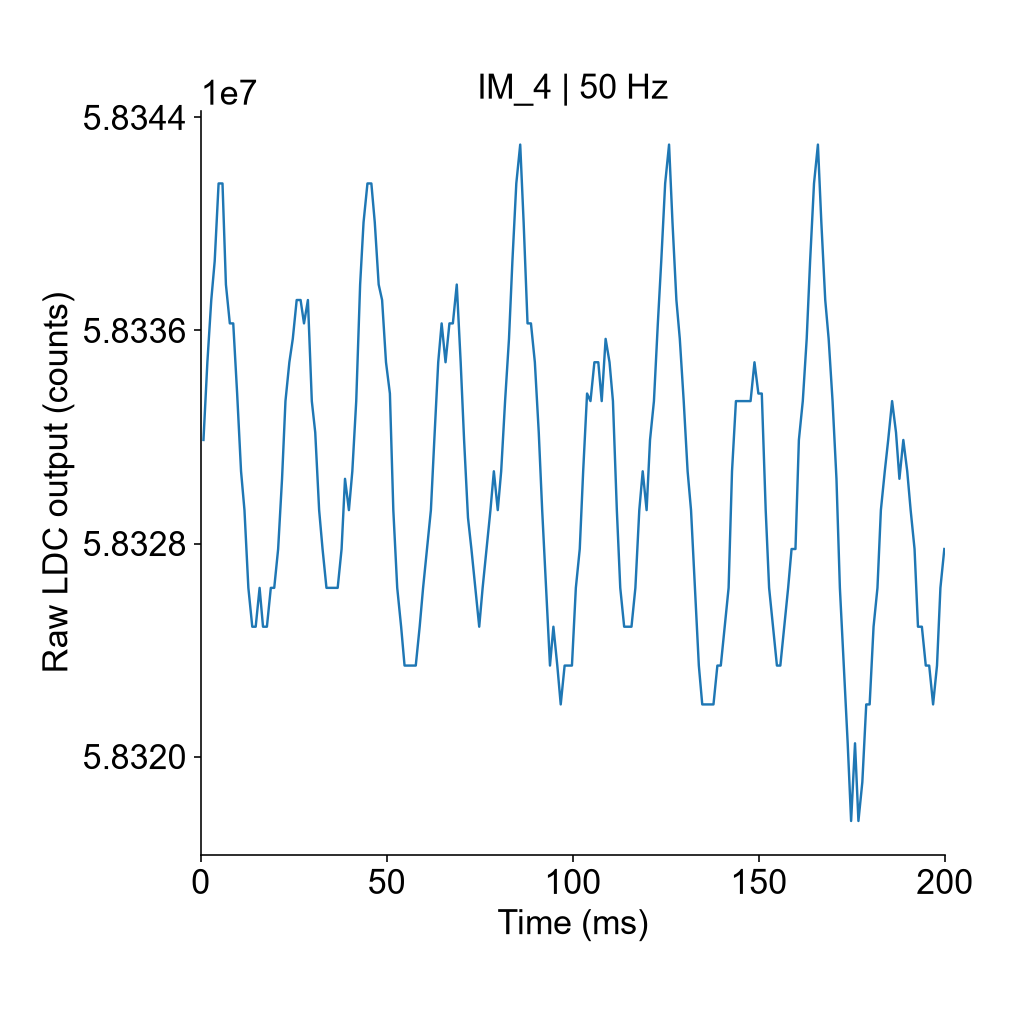

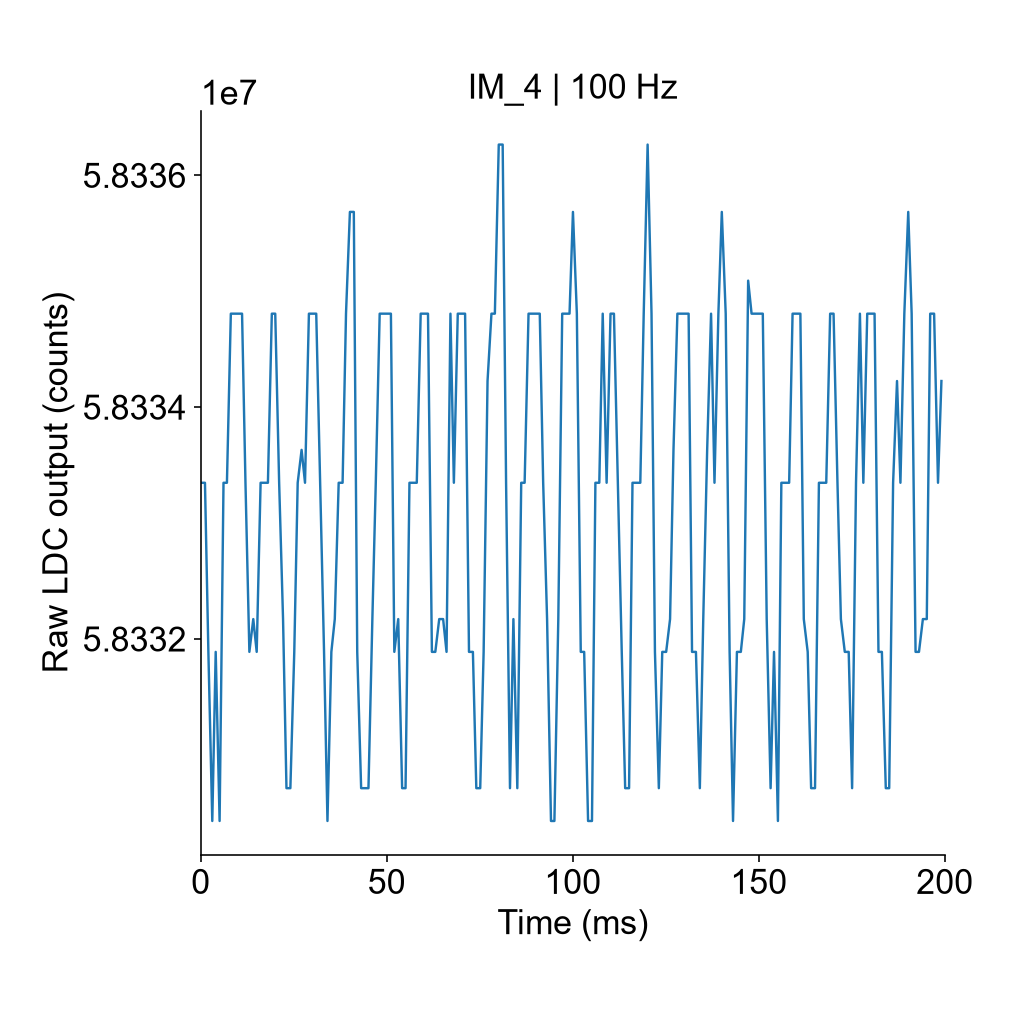

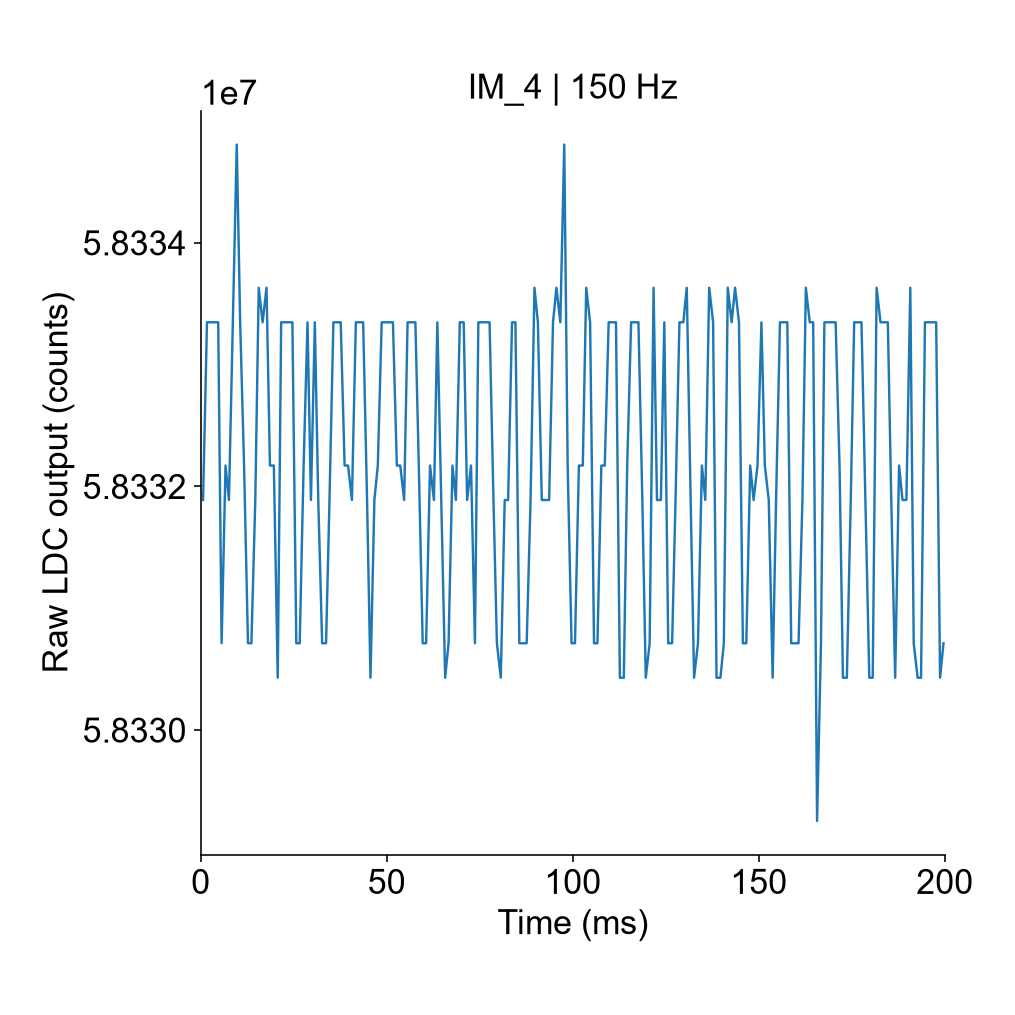

In [2]:
# Regenerate three raw-frequency views from the selected recording.
import data11_record_review as review
importlib.reload(review)
RAW_RESULTS = review.export_raw_examples(
    RAW_FREQUENCIES_HZ, raw_file=RAW_FILE, window_ms=RAW_WINDOW_MS,
    notebook_path=NOTEBOOK_PATH, tracking=CONFIG)
print('PNG / SVG / CSV output:', RAW_RESULTS['output_path'])
display(RAW_RESULTS['windows'])
for image_path in RAW_RESULTS['figures']:
    if Path(image_path).stem.endswith('_' + RAW_DISPLAY):
        display(Image(filename=image_path))
        # Embed the existing SVG for download even when results are on another drive.
        from base64 import b64encode
        from html import escape
        from IPython.display import HTML
        svg_path = Path(image_path).with_suffix('.svg')
        if not svg_path.is_file():
            raise FileNotFoundError(f'SVG export missing: {svg_path}')
        svg_data = b64encode(svg_path.read_bytes()).decode('ascii')
        display(HTML(
            f'<p><a download="{escape(svg_path.name, quote=True)}" '
            f'href="data:image/svg+xml;base64,{svg_data}">'
            f'Download SVG: {escape(svg_path.name)}</a></p>'
            f'<p>Saved SVG: <code>{escape(str(svg_path))}</code></p>'
        ))
# Both raw and detrended exports are saved; the raw preview retains DC.


## Reference conditions and scope

IM and accelerometer recordings were acquired in separate batches. Matching drive settings, position and load were reported for this experiment. `Raw_Z * 0.000488` is a nominal g/count conversion, not an individual frequency-response calibration. Report nominal responsivity in counts/g, without synchronized phase, coherence, V/Pa or calibrated sensitivity.

The recorded excitation setting was a 30-300 Hz logarithmic sweep over 30 s; this does not establish each file's start time or actual mechanical amplitude. Public references describe harmonic extraction and comparison principles: [Siemens sine data reduction](https://community.sw.siemens.com/articles/en_US/Knowledge/Sine-Data-Reduction), [amplitude estimation](https://community.sw.siemens.com/articles/en_US/Knowledge/sine-control-amplitude-estimation-methods), and the scope of [ISO 16063-21](https://www.iso.org/standard/27053.html) with [Amendment 2](https://www.iso.org/standard/85624.html). No complete standards-based calibration is claimed.


In [3]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
from IPython.display import display, Image

for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "release_manifest.json").is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break
from portable_runtime import project_root, data_root, ensure_environment, notebook_path
PROJECT = project_root()
ensure_environment()
NOTEBOOK_PATH = notebook_path("data11_frequency_range_analysis")
import data11_harmonic_tracking as ht
importlib.reload(ht)
print('Python:', sys.executable)

# Reload the shared paper figure style for this Run All.
import importlib as _paper_importlib
import paper_figure_style as _paper_style
_paper_importlib.reload(_paper_style)


Python: c:\Users\kangb3\Desktop\Research\Inductive Microphone\.venv\Scripts\python.exe


<module 'paper_figure_style' from 'c:\\Users\\kangb3\\Desktop\\Research\\Inductive Microphone\\Figure2and3\\paper_figure_style.py'>

## Tracking settings

The top configuration remains authoritative: one selected sweep per enabled material, accelerometer sweep 3, a 0.8 s Hann kernel, 81 logarithmic frequency points, a 10 dB threshold and at least one accepted sweep. Unassigned files are not added automatically; missing inputs are recorded.

The 15-420 Hz tracker search bounds are analysis limits, not a demonstrated response range. Nominal Hann ENBW is 1.875 Hz. Grid spacing, sweep span within a window and ENBW are distinct; denser plotting does not improve physical frequency resolution.


In [4]:
# Retain CONFIG from the selection cell.
display(pd.DataFrame([{'material': name, 'noise_ids': ids[0], 'sweep_ids': ids[1]}
                      for name, ids in CONFIG['materials'].items()]))
print('Data:', CONFIG['data_root'])
print('Accelerometer sweeps:', CONFIG['accel_sweeps'])


,material,noise_ids,sweep_ids
0,OO-50 0.23 mm,"[1, 2]",[4]
1,10 NV,"[18, 19]",[20]
2,945,"[23, 24]",[27]
3,18,"[33, 34]",[36]
4,OO-50 4.05 mm,"[38, 39]",[42]
5,Foam 4.17 mm,"[43, 44]",[46]
6,"OO-50 large coil, silicone bonded, 3.5 uH","[49, 50]",[52]


Data: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\data\Data11
Accelerometer sweeps: [3]


## Review the selected sweeps

Only the configured selection is reviewed. Audits identify endpoint, timestamp, sampling and trajectory issues. Recommendations do not overwrite the manual selection.


In [5]:
import data11_record_review as review
importlib.reload(review)
REVIEW_CONFIG = review.review_config()
REVIEW_CONFIG['tracking'] = deepcopy(CONFIG)
REVIEW_CONFIG['amplitude_ids'] = []
REVIEW_CONFIG['include_raw_examples'] = False
REVIEW_RESULTS = review.run_review(REVIEW_CONFIG, NOTEBOOK_PATH)
REVIEW_OUTPUT_PATH = Path(REVIEW_RESULTS['output_path'])
display(REVIEW_RESULTS['audit'])
display(REVIEW_RESULTS['selection'])
print('Review output:', REVIEW_OUTPUT_PATH)


REVIEW_OUTPUT: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_candidate_review_run001
Review: IM_4.csv
Review: IM_20.csv
Review: IM_27.csv
Review: IM_36.csv
Review: IM_42.csv
Review: IM_46.csv
Review: IM_52.csv


,file,material,role,recommended,quality_candidate,samples,duration_s,fs_hz,dt_median_s,dt_cv,...,inferred_f0_to_f1_duration_s,nominal_duration_s,nominal_comparison_basis,duration_relative_error,schedule_review_flag,linear_local_slope_hz_per_s,linear_local_rmse_hz,log_model_local_rmse_hz,supported_grid_points,review_reason
0,IM_4.csv,OO-50 0.23 mm,sweep_candidate,True,True,35972,35.979289,999.769617,0.001049,0.063386,...,30.135799,30.0,onset_aligned_shape_only,0.004527,False,7.049310,24.278658,0.713124,78,Pass existing gates and jump review screen
1,IM_20.csv,10 NV,sweep_candidate,True,True,37634,37.641578,999.772114,0.001049,0.063396,...,30.128119,30.0,onset_aligned_shape_only,0.004271,False,7.872665,20.478421,0.102452,77,Pass existing gates and jump review screen
2,IM_27.csv,945,sweep_candidate,True,True,36313,36.320317,999.771010,0.001049,0.063394,...,30.136197,30.0,onset_aligned_shape_only,0.004540,False,8.148980,20.508987,0.075568,78,Pass existing gates and jump review screen
3,IM_36.csv,18,sweep_candidate,True,True,35933,35.940167,999.772761,0.001049,0.063394,...,30.134327,30.0,onset_aligned_shape_only,0.004478,False,7.592141,21.603929,0.641025,77,Pass existing gates and jump review screen
4,IM_42.csv,OO-50 4.05 mm,sweep_candidate,True,True,36019,36.026165,999.773359,0.001049,0.063403,...,30.144344,30.0,onset_aligned_shape_only,0.004811,False,7.466710,23.706877,0.683140,78,Pass existing gates and jump review screen
5,IM_46.csv,Foam 4.17 mm,sweep_candidate,True,True,36774,36.781401,999.771597,0.001049,0.063393,...,30.138768,30.0,onset_aligned_shape_only,0.004626,False,7.415397,16.245654,0.089240,72,Pass existing gates and jump review screen
6,IM_52.csv,"OO-50 large coil, silicone bonded, 3.5 uH",sweep_candidate,True,True,36203,36.210286,999.771170,0.001049,0.063394,...,30.125128,30.0,onset_aligned_shape_only,0.004171,False,8.198132,20.612558,0.067709,78,Pass existing gates and jump review screen


,material,selected_ids,count,requested,status
0,OO-50 0.23 mm,[4],1,3,insufficient passing records
1,10 NV,[20],1,3,insufficient passing records
2,945,[27],1,3,insufficient passing records
3,18,[36],1,3,insufficient passing records
4,OO-50 4.05 mm,[42],1,3,insufficient passing records
5,Foam 4.17 mm,[46],1,3,insufficient passing records
6,"OO-50 large coil, silicone bonded, 3.5 uH",[52],1,3,insufficient passing records


Review output: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_candidate_review_run001


In [6]:
# Preserve manual selection; do not apply recommended_config automatically.
display(pd.DataFrame([{'material': k, 'noise_ids': v[0], 'selected_sweep_ids': v[1]}
                      for k, v in CONFIG['materials'].items()]))


,material,noise_ids,selected_sweep_ids
0,OO-50 0.23 mm,"[1, 2]",[4]
1,10 NV,"[18, 19]",[20]
2,945,"[23, 24]",[27]
3,18,"[33, 34]",[36]
4,OO-50 4.05 mm,"[38, 39]",[42]
5,Foam 4.17 mm,"[43, 44]",[46]
6,"OO-50 large coil, silicone bonded, 3.5 uH","[49, 50]",[52]


## Estimator and SNR

For $\tau=t-t_c$ and fitted logarithmic sweep rate $k$:

$$\phi(\tau)=2\pi f_c\frac{\exp(k\tau)-1}{k},\qquad z=2\sum_n w_n[x_n-\widehat{a+b\tau_n}]e^{-i\phi_n}.$$

Normalized weights combine trapezoidal timestamp integration with a Hann kernel; the linear trend uses the same weights. Fundamental peak amplitude is $|z|$, and RMS is $|z|/\sqrt{2}$. These differ from peak-to-peak, total RMS and FFT-bin amplitude. Only complete centered windows are used; changing amplitude or phase within a window is smoothed.

Background windows use the same $f_c,k,T$, without searching for a noise peak:

$$N_{eq,peak}=\sqrt{\frac1M\sum_j|z_{noise,j}|^2},\quad SNR_{lin}=A_{1,peak}/N_{eq,peak},\quad SNR_{dB}=20\log_{10}(SNR_{lin}).$$

Nominal two-sided baseband Hann ENBW is $1.5/T$. The saved detrended discrete kernel gives $B_{eff}=f_s\sum|h|^2/4$; with nonuniform sampling this is not an established analog bandwidth. Noise/signal kernel bandwidths must agree within 3%, with at least four accepted nonoverlapping noise windows. Overlapping signal windows are not independent repeats.

Both noise conditions are retained; detectable intervals use amplifier-on noise. Fundamental RMS / full recorded-band noise RMS is also saved as a separate broadband SNR. No noise-power subtraction is applied. Positive low-SNR amplitude bias and trajectory-selection bias remain. The threshold is not a false-alarm-calibrated detection limit.


## Figure y-axis upper limits

Each group has three upper y limits, ordered from top to bottom: fundamental amplitude (counts), SNR (dB), and nominal responsivity (counts/g). Use `None` for an automatic limit. These settings affect figure display only. After editing, run the control cell below and then the analysis cell; to redraw existing results without rerunning the analysis, use the optional redraw cell at the end of this notebook.


In [7]:
# Upper y limits, ordered top to bottom: amplitude, SNR, responsivity.
# Use None for an automatic upper limit in any panel.
PLOT_YMAX = {
    'materials': [40000, 120, 80000],
    'coil_design': [150000, 85, 40000],
}


## Execute and save

Each run saves figures, CSV summaries, noise-window audits, effective parameters, input roles and hashes, Git status, exact published source snapshots, methods and completion status. Dates use America/New_York. Missing or rejected data are reported; previous runs are never overwritten.


In [8]:
# Reload implementations without resetting the user's edited CONFIG.
RESULTS = None
OUTPUT_PATH = None
for module_name in ['characterization_run', 'data11_config', 'resolution_sine_fit',
                    'data11_analysis', 'data11_harmonic_tracking']:
    module = importlib.import_module(module_name)
    importlib.reload(module)
ht = sys.modules['data11_harmonic_tracking']
shell = get_ipython()
live_cells = list(shell.history_manager.input_hist_raw) if shell is not None else []
RESULTS = ht.run_tracking(CONFIG, NOTEBOOK_PATH,
                          executed_cells=live_cells, plot_ymax=PLOT_YMAX)
OUTPUT_PATH = Path(RESULTS['output_path'])
print('Exact output path:', OUTPUT_PATH)


Output directory: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_harmonic_tracking_run001
Harmonic tracking: IM_4.csv


c:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\data11_harmonic_tracking.py:564: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); save_fig(run,fig,Path(r['file']).stem+'_harmonic_tracking',figures)


Harmonic tracking: IM_20.csv
Harmonic tracking: IM_27.csv
Harmonic tracking: IM_36.csv
Harmonic tracking: IM_42.csv


c:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\data11_harmonic_tracking.py:564: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(); save_fig(run,fig,Path(r['file']).stem+'_harmonic_tracking',figures)


Harmonic tracking: IM_46.csv
Harmonic tracking: IM_52.csv
Harmonic tracking: accel_3.csv
Exact output path: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_harmonic_tracking_run001


## Frequency trajectory and nominal comparison

Check that the ridge follows the fundamental and that a global logarithmic model is adequate. The ridge is initialized from data, but the model and search bounds remain assumptions; strong harmonics can be mistaken for the fundamental.

Without an independent drive/trigger channel, the nominal curve is only an onset-aligned shape comparison. Inferred 30-to-300 Hz crossing times are model estimates, not measured switching times or independent instrument validation.


,file,log_intercept,rate_per_s,trajectory_ok,coherent_points,log_frequency_rmse,support_start_s,support_end_s,inferred_f0_crossing_s,inferred_f0_to_f1_duration_s,nominal_duration_s,nominal_comparison_basis
0,IM_4.csv,2.963275,0.076407,True,60,0.000924,5.900000,35.400000,5.731451,30.135799,30.0,onset_aligned_shape_only
1,IM_20.csv,2.862668,0.076426,True,59,0.000907,7.451470,36.451470,7.046380,30.128119,30.0,onset_aligned_shape_only
2,IM_27.csv,2.966517,0.076406,True,60,0.001354,5.851340,35.351340,5.689086,30.136197,30.0,onset_aligned_shape_only
3,IM_36.csv,2.972536,0.076411,True,59,0.001389,6.100818,35.100818,5.609962,30.134327,30.0,onset_aligned_shape_only
4,IM_42.csv,2.983949,0.076385,True,60,0.001723,5.900000,35.400000,5.462410,30.144344,30.0,onset_aligned_shape_only
5,IM_46.csv,2.919579,0.076399,True,53,0.001398,6.451474,33.451474,6.303945,30.138768,30.0,onset_aligned_shape_only
6,IM_52.csv,2.971722,0.076434,True,60,0.000905,5.851339,35.351339,5.618909,30.125128,30.0,onset_aligned_shape_only
7,accel_3.csv,2.966012,0.076413,True,59,0.001686,5.704233,35.204233,5.695191,30.133490,30.0,onset_aligned_shape_only


,file,samples,duration_s,fs_hz,dt_median_s,dt_cv,max_gap_ratio,gap_count,unit,scale,timestamp_valid,raw_min,raw_max,endpoint_code_count,role,material
0,IM_1.csv,60426,60.438800,999.771670,0.001049,0.063378,1.000953,0,counts,1.000000,True,58422094.0,58444566.0,0,noise,OO-50 0.23 mm
1,IM_2.csv,101169,101.191047,999.772243,0.001049,0.063386,1.000953,0,counts,1.000000,True,58422094.0,58442560.0,0,noise,OO-50 0.23 mm
2,IM_4.csv,35972,35.979289,999.769617,0.001049,0.063386,1.000953,0,counts,1.000000,True,58290722.0,58345899.0,0,sweep,OO-50 0.23 mm
3,IM_18.csv,60798,60.811010,999.769614,0.001049,0.063383,1.000953,0,counts,1.000000,True,51663013.0,51682118.0,0,noise,10 NV
4,IM_19.csv,40362,40.370348,999.768444,0.001049,0.063394,1.000953,0,counts,1.000000,True,51668184.0,51685996.0,0,noise,10 NV
5,IM_20.csv,37634,37.641578,999.772114,0.001049,0.063396,1.000953,0,counts,1.000000,True,51663013.0,51735834.0,0,sweep,10 NV
6,IM_23.csv,60499,60.511907,999.770177,0.001049,0.063398,1.000953,0,counts,1.000000,True,56669260.0,56702164.0,0,noise,945
7,IM_24.csv,62752,62.765205,999.773680,0.001049,0.063398,1.000953,0,counts,1.000000,True,56659410.0,56694783.0,0,noise,945
8,IM_27.csv,36313,36.320317,999.771010,0.001049,0.063394,1.000953,0,counts,1.000000,True,56467136.0,56672468.0,0,sweep,945
9,IM_33.csv,40272,40.280303,999.769043,0.001049,0.063377,1.000953,0,counts,1.000000,True,56935361.0,56970767.0,0,noise,18


Input issues: []
Unavailable sweeps: []


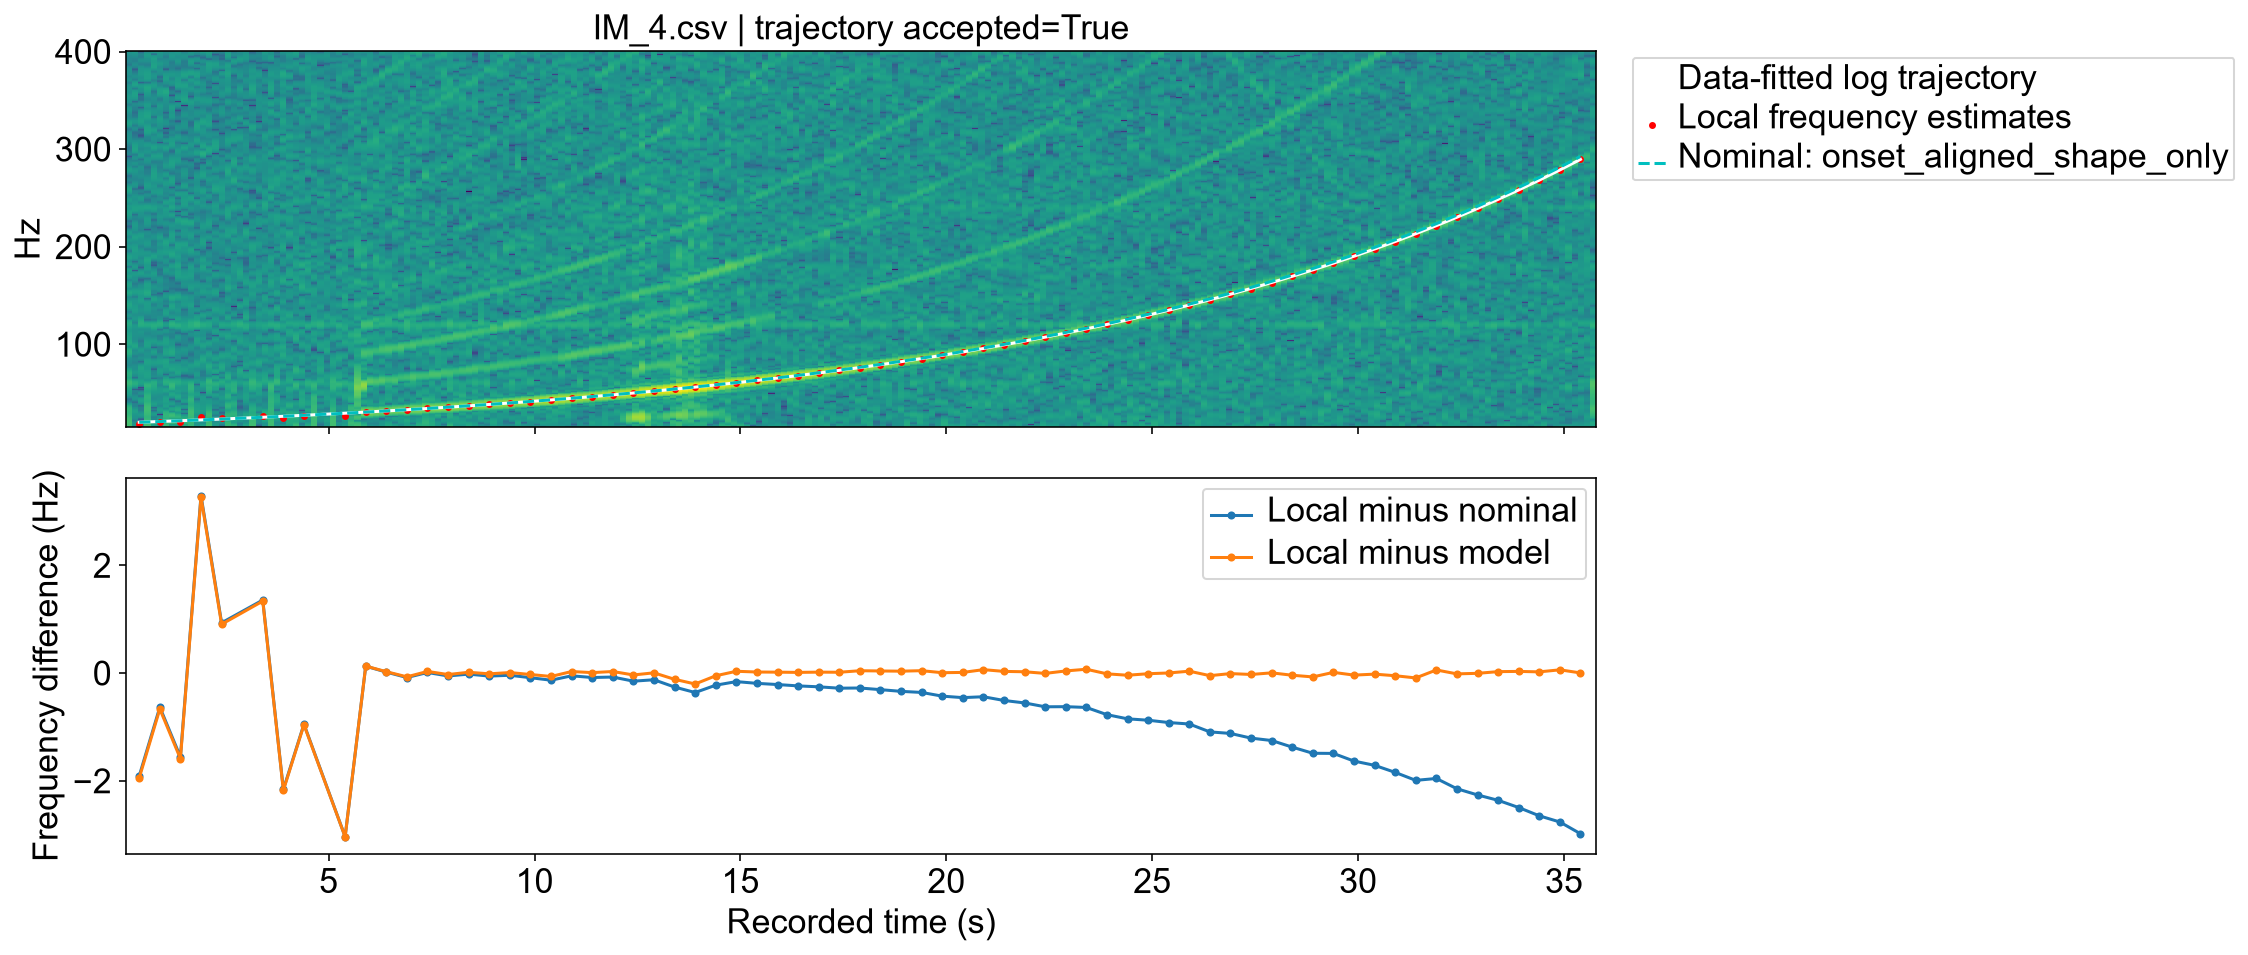

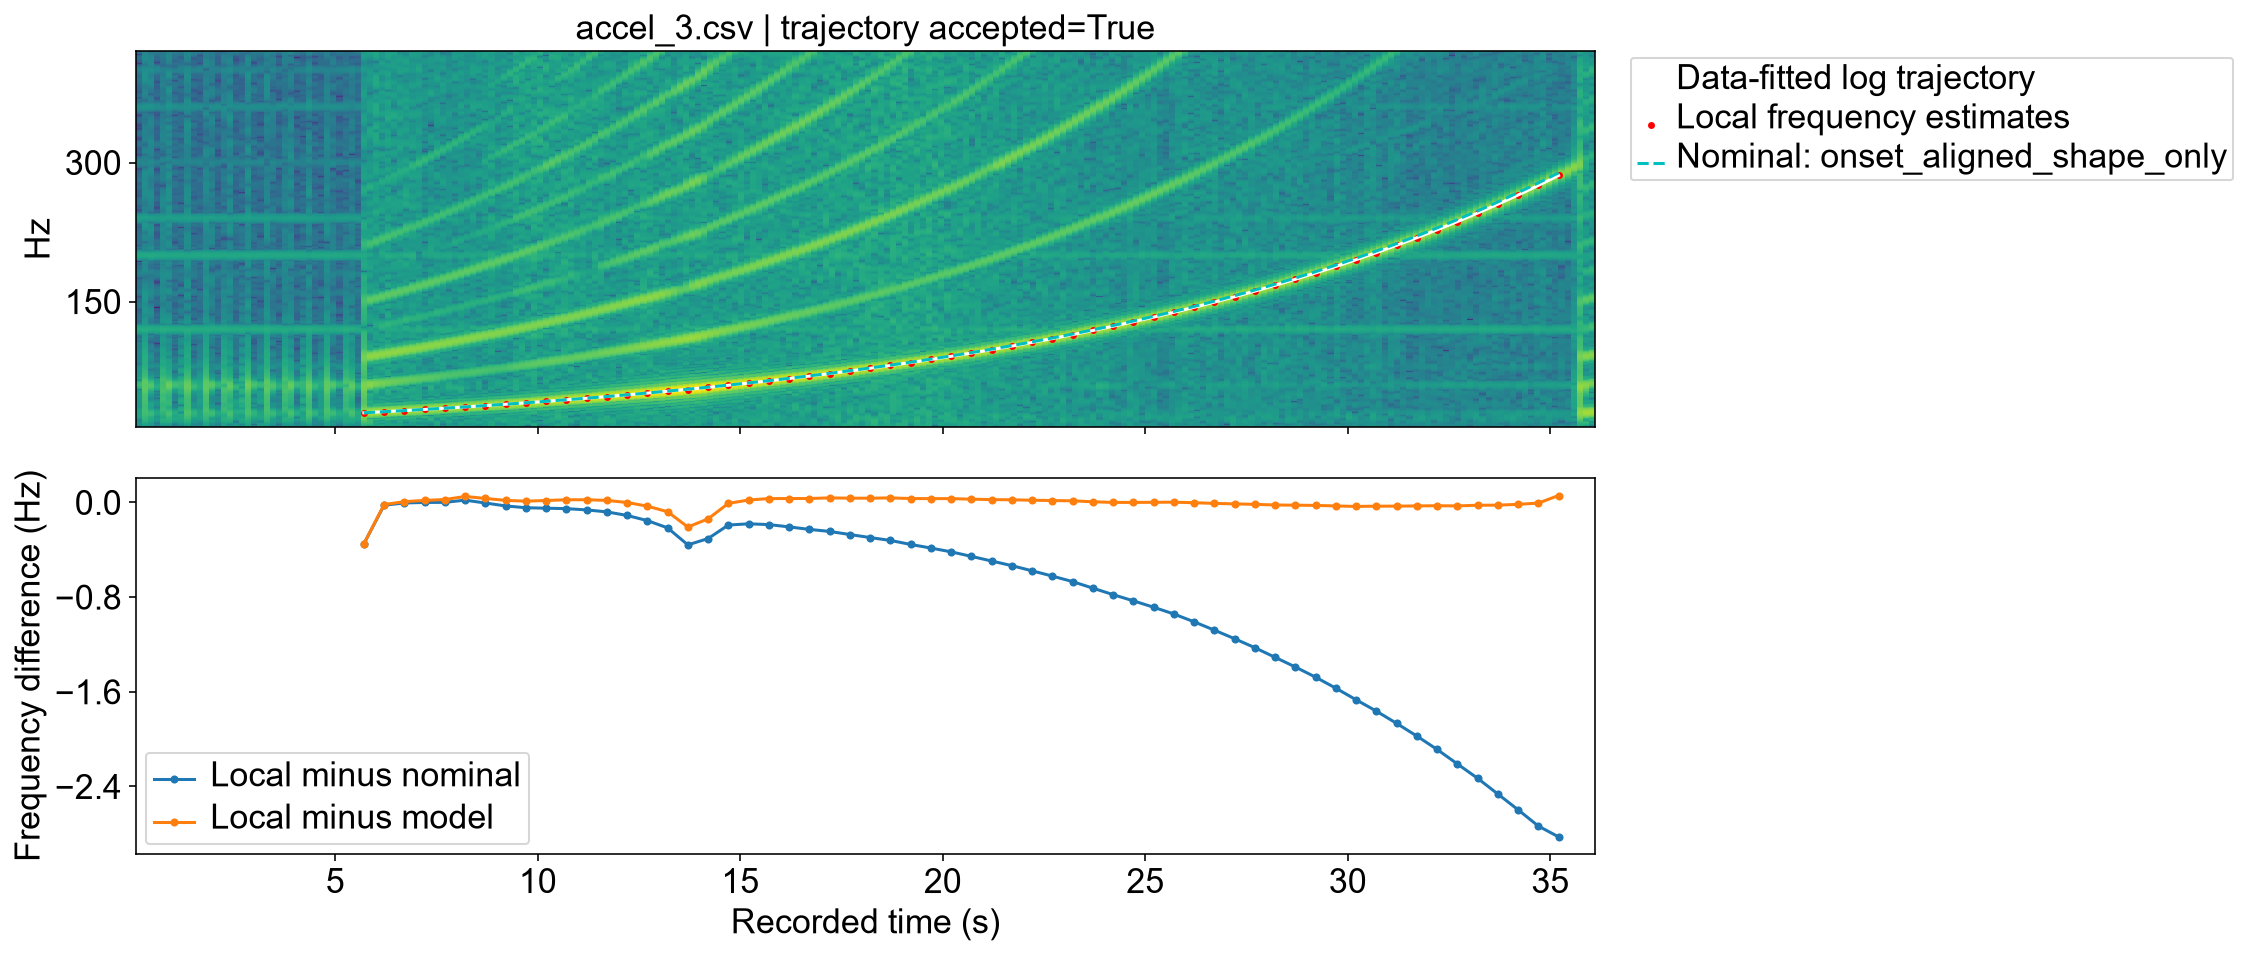

In [9]:
if RESULTS is None:
    raise RuntimeError('Run the analysis cell successfully first.')
display(RESULTS['trajectories'])
display(RESULTS['audit'])
print('Input issues:', RESULTS['input_issues'])
print('Unavailable sweeps:', RESULTS['unavailable_records'])

def show_figures(*keywords):
    for path in RESULTS['figures']:
        if any(word in Path(path).name for word in keywords):
            display(Image(filename=str(path)))

# Show one IM and one reference; all per-file plots are saved.
show_figures(f'{Path(RAW_FILE).stem}_harmonic_tracking',
             f'accel_{CONFIG["accel_sweeps"][0]}_harmonic_tracking')


## Amplitude, SNR and nominal responsivity

Each amplitude and SNR curve uses the selected single recording. Main comparison figures show connected nominal responsivity, and the separate accelerometer-reference figure uses the same existing reference estimates for its amplitude and SNR displays. Strict comparisons and the strict accelerometer-reference figure, with unavailable reference points, are displayed in the supplement. The standalone fundamental-amplitude figure repeats the first panel of the corresponding comparison figure. Strict numerical results exclude an entire IM recording with numerical Data28 endpoint anomalies and require acceptable local timestamps, sampling rate and window coverage. Local chirp-fit fraction is diagnostic only. Missing or rejected points remain unavailable.

For the published one-record-per-sensor selection:

$$R_a(f)=A_{IM,1,peak}(f)/A_{accel,1,peak}(f)\quad[\mathrm{counts}/g].$$

Both displays retain the SNR, record-count and reference-condition requirements. The connected display uses the existing reference estimates documented in METHODS.md and the per-point presentation tables; strict CSV eligibility and detectable intervals remain separate. The sensors were acquired independently; no temporal or file-by-file pairing is implied. Divide counts/g by 9.80665 for counts/(m/s²). No complete calibrated sensitivity uncertainty interval is claimed.

CSV fields retain their existing `_mean` and `_sd` names for compatibility. With one accepted record, `_mean` equals that record's estimate and between-record `_sd` is NaN. Reusing background data or overlapping frequency windows adds no independent repeats. If multiple sweeps are explicitly selected later, the documented arithmetic-mean and sample-SD aggregation applies.


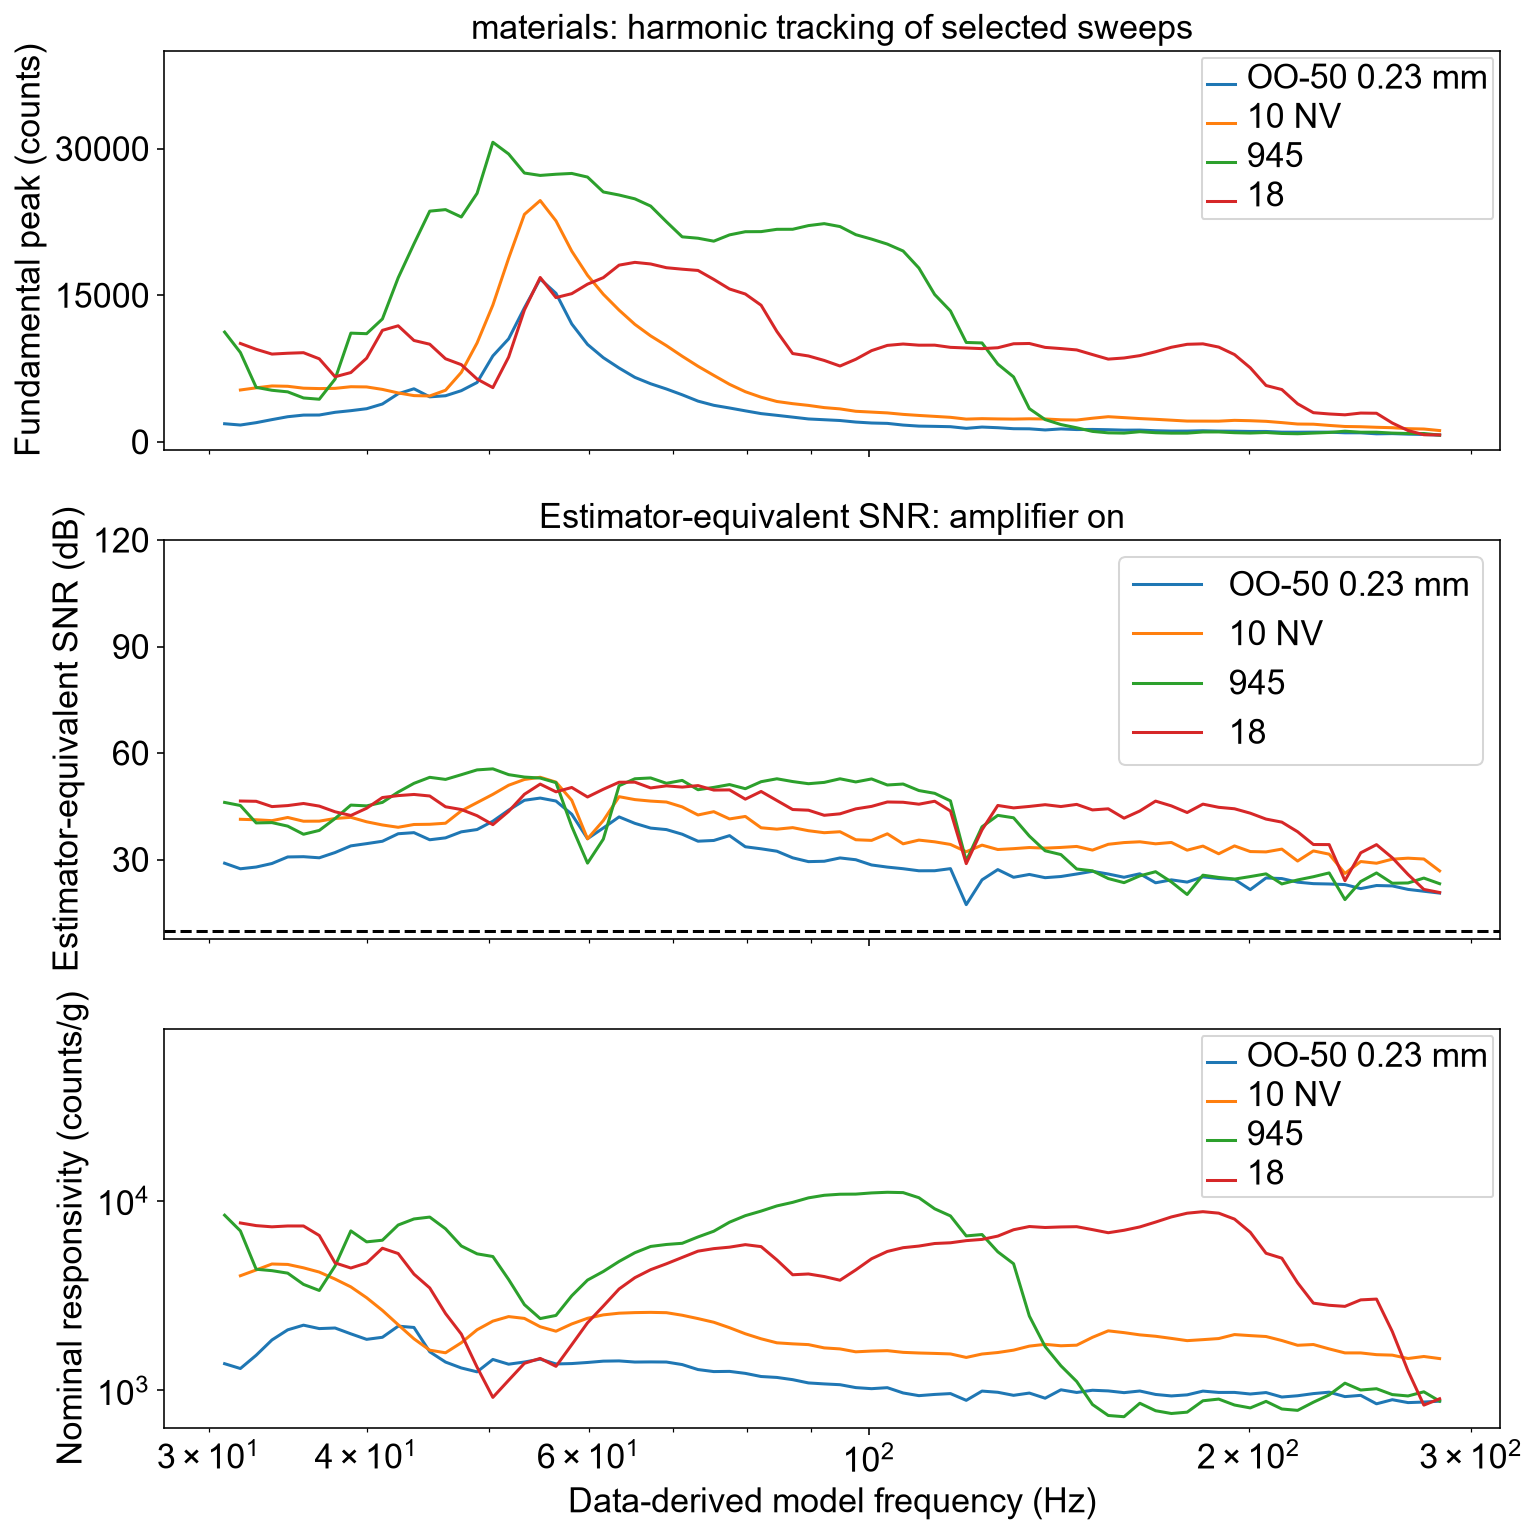

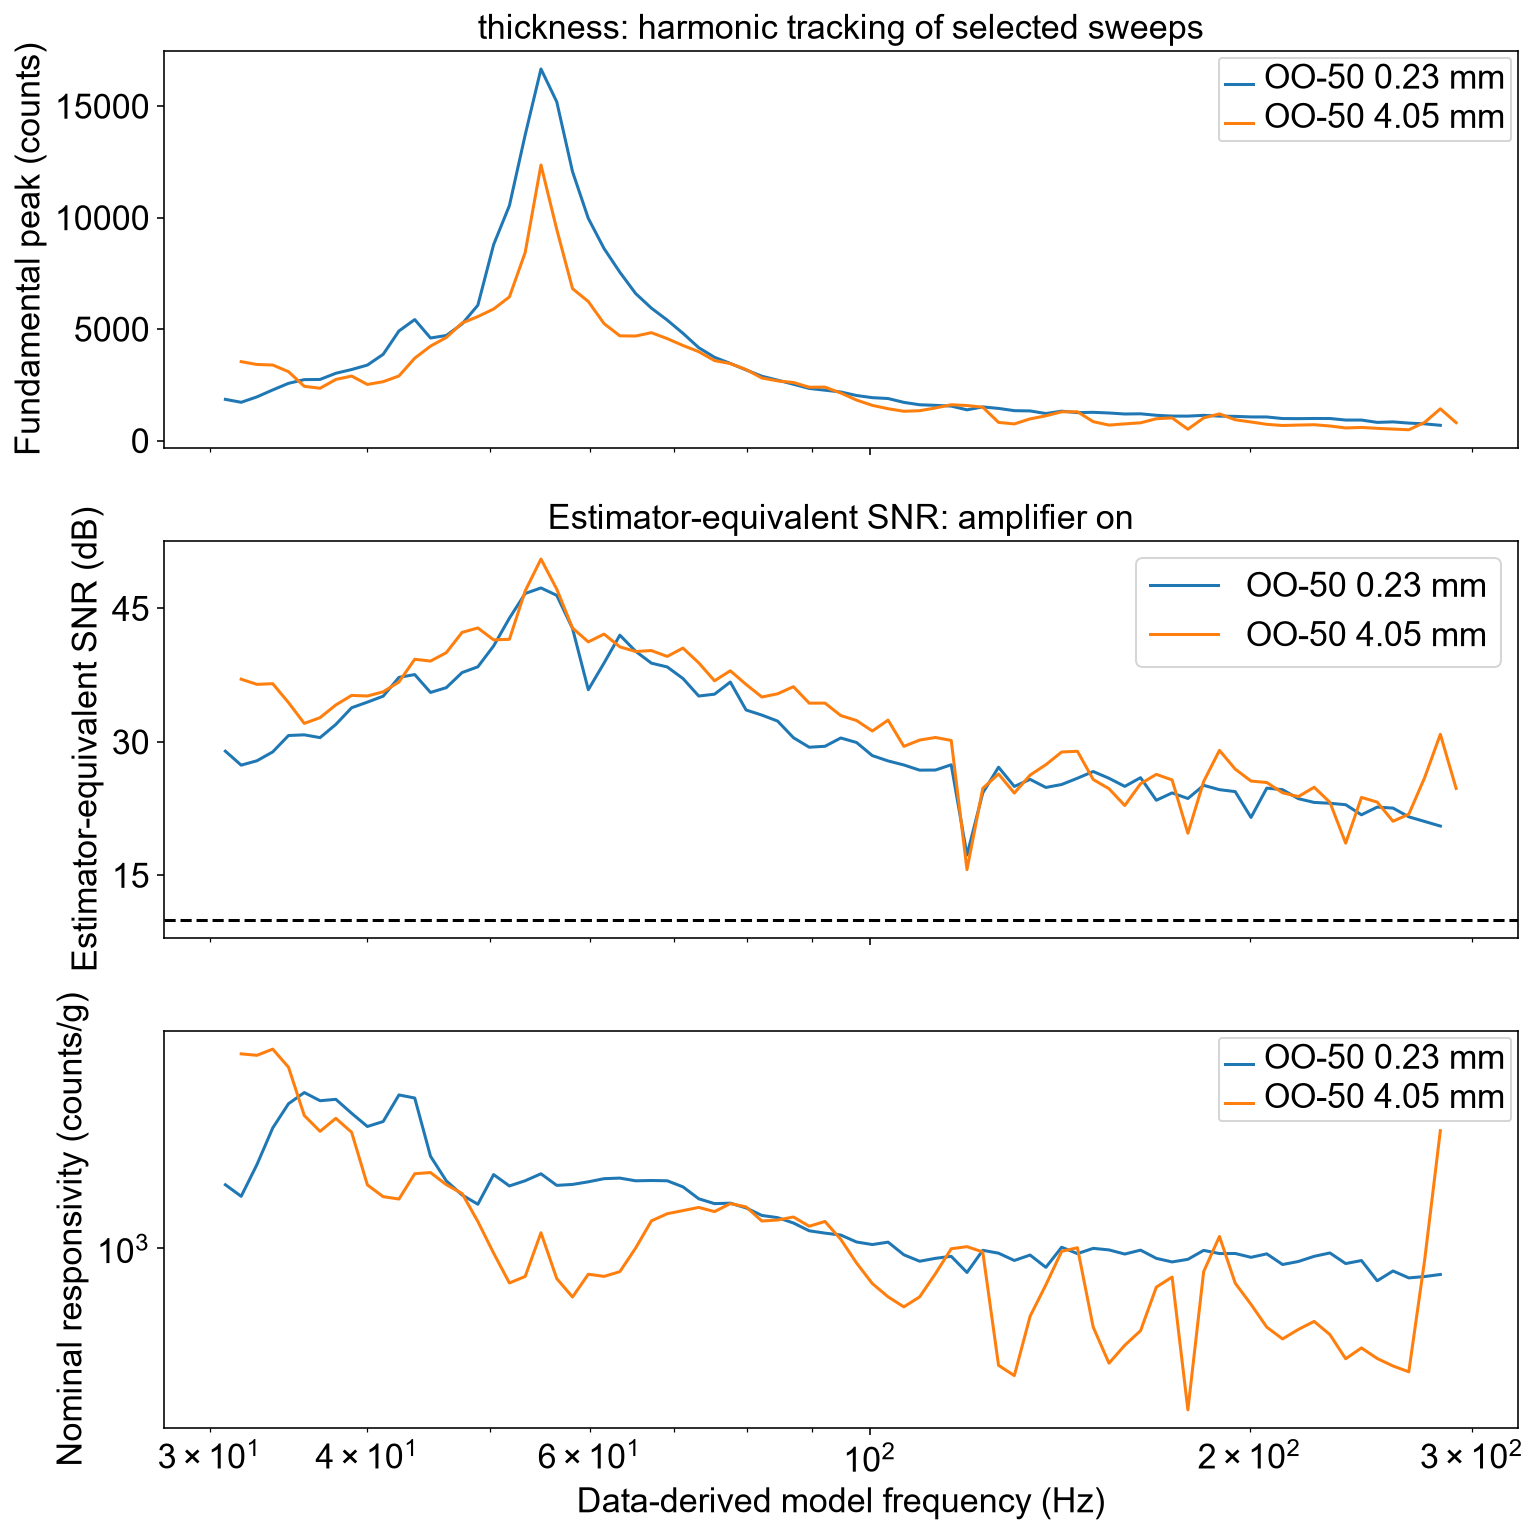

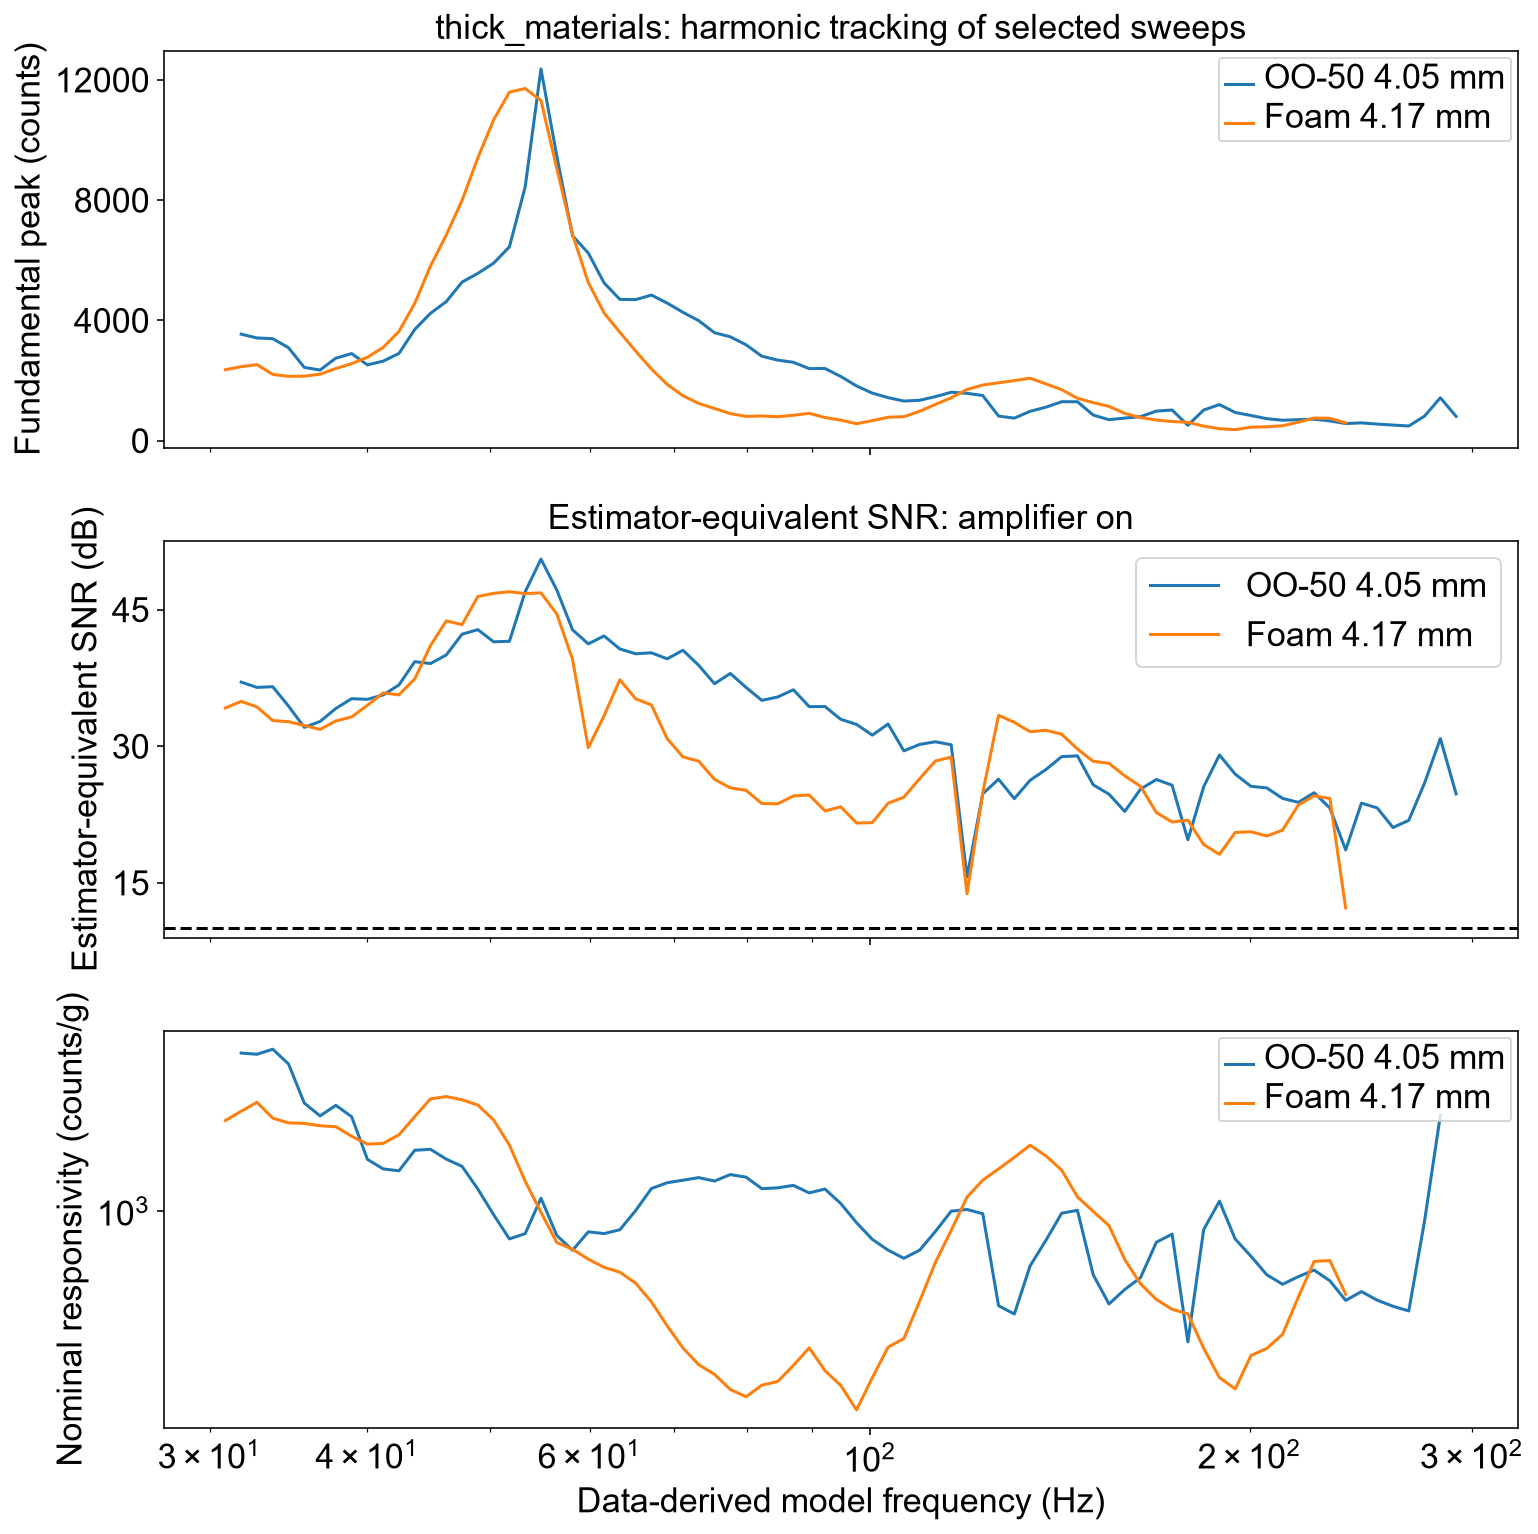

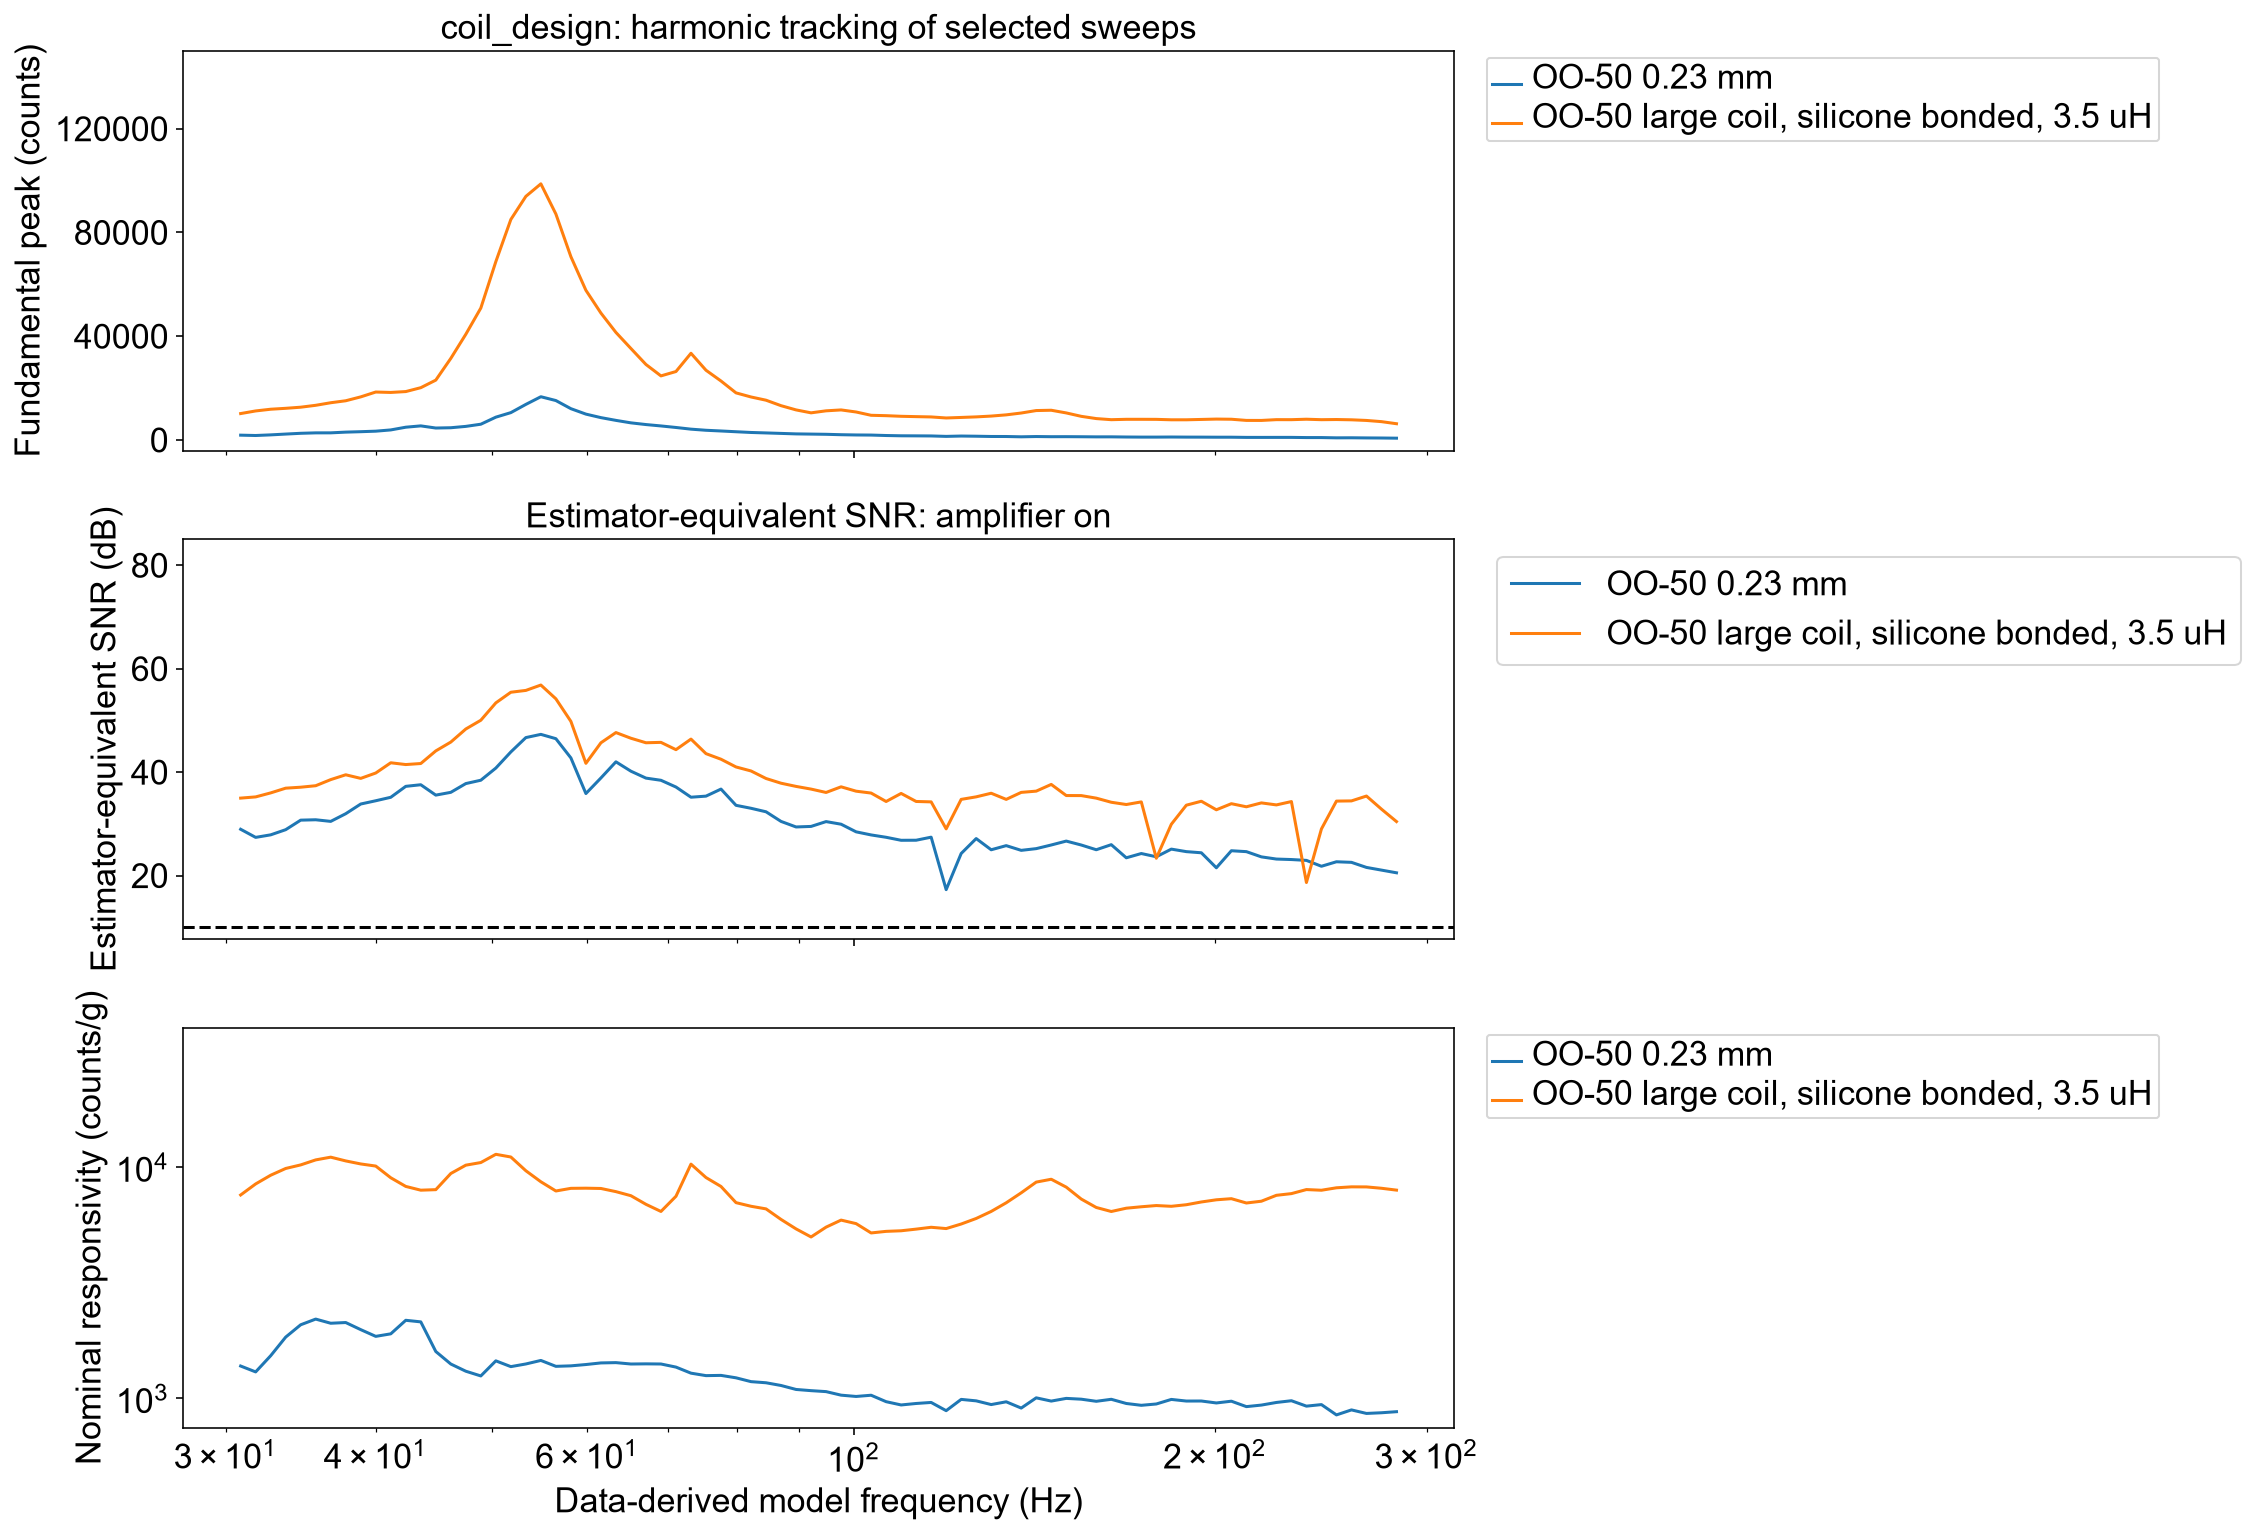

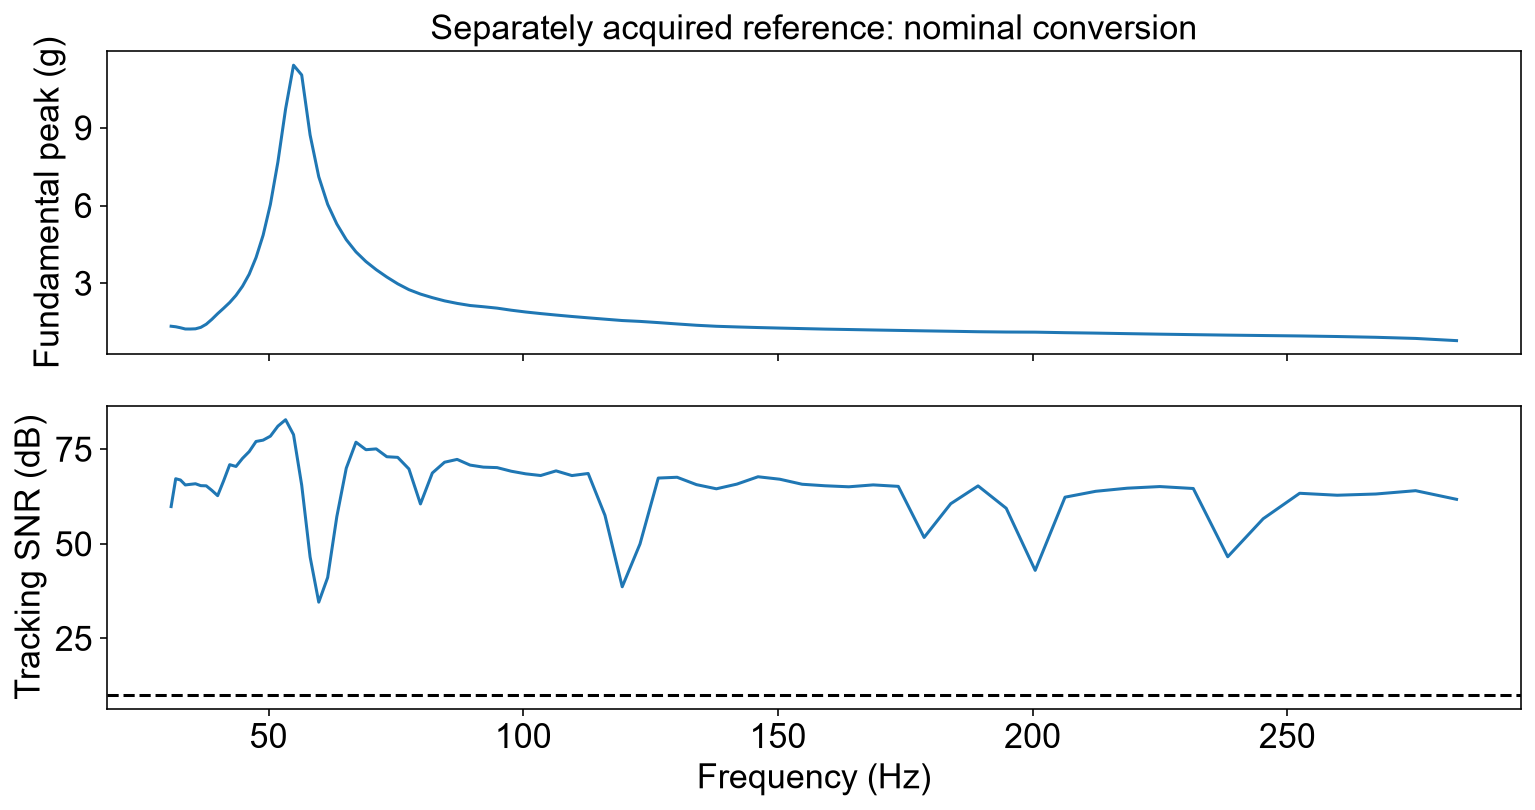

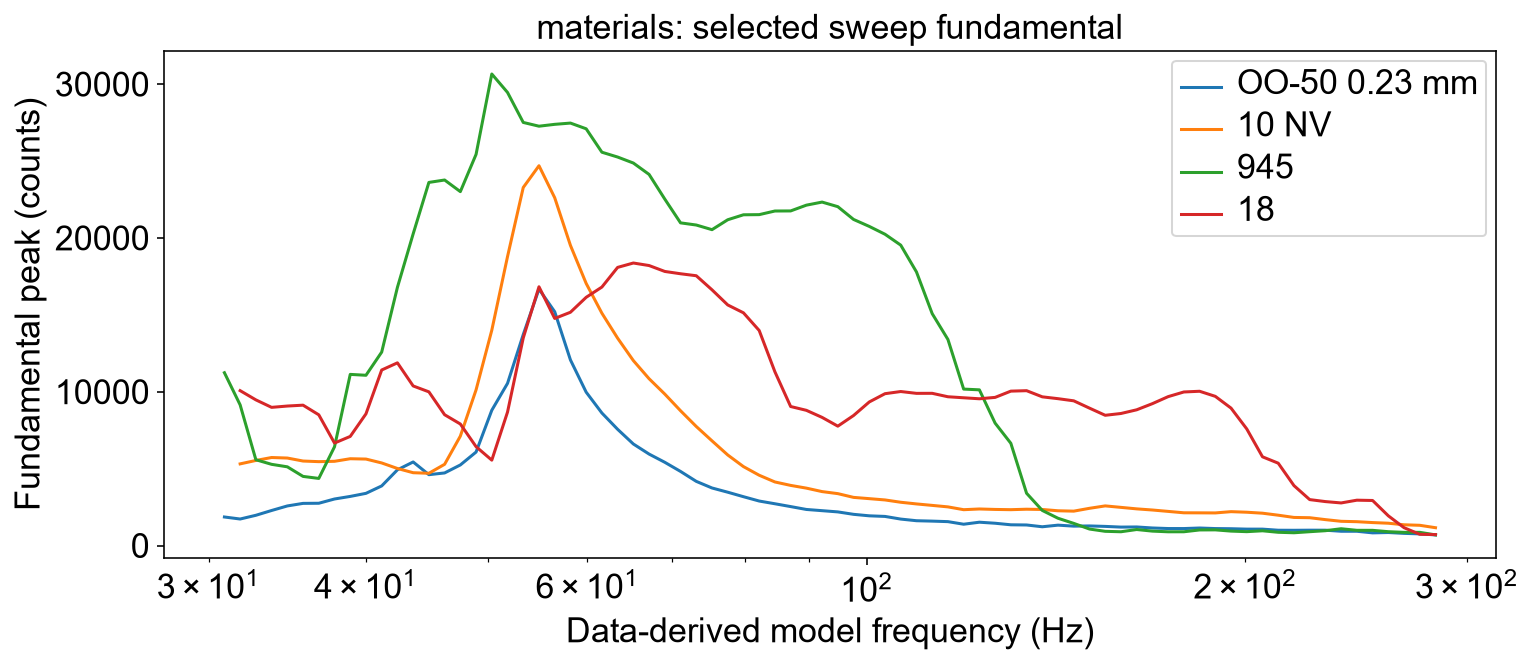

,first_supported_hz,last_supported_hz,supported_grid_points,minimum_counts_per_g,maximum_counts_per_g
material,,,,,
10 NV,31.777612,283.218263,75,1469.416455,4628.827308
18,31.777612,283.218263,75,835.415529,8732.369109
945,30.876016,283.218263,76,725.770426,11050.888456
Foam 4.17 mm,30.876016,238.298470,70,288.352149,2043.059084
OO-50 0.23 mm,30.876016,283.218263,76,848.729203,2203.689817
OO-50 4.05 mm,31.777612,283.218263,75,441.112653,2746.402830
"OO-50 large coil, silicone bonded, 3.5 uH",30.876016,283.218263,76,4992.210568,11369.472504


In [10]:
# RESULTS['figures'] contains main views; strict comparison views are in the supplement.
show_figures('tracking_comparison_', 'tracking_accelerometer_reference')
show_figures('tracking_fundamental_materials_no_region')
display(RESULTS['reference'].query('eligible').groupby('material').agg(
    first_supported_hz=('frequency_hz', 'min'), last_supported_hz=('frequency_hz', 'max'),
    supported_grid_points=('frequency_hz', 'size'),
    minimum_counts_per_g=('counts_per_g', 'min'), maximum_counts_per_g=('counts_per_g', 'max')))
# First/last values are an overview and may contain internal gaps.


## Demonstrated detectable intervals

For the published selection, a point requires the selected sweep to pass the quality checks and its amplifier-on SNR to be strictly above the threshold. Only adjacent accepted grid points are merged; gaps are not bridged, cutoffs are not interpolated and unmeasured regions are not extrapolated. One point does not establish a continuous band. Coverage depends on excitation, noise, bandwidth and threshold; it is not intrinsic bandwidth or acoustic frequency response.

The accepted-record count below is at most one per material in the published configuration. `minimum_repeat_count` is the retained internal setting for that count requirement.


,material,start_hz,end_hz,grid_points,minimum_n,threshold_db,minimum_group_snr_db,interpretation
0,OO-50 0.23 mm,30.876016,283.218263,78,1,10.0,17.283780,tested adjacent grid points; no interpolated c...
1,10 NV,31.777612,283.218263,77,1,10.0,26.074962,tested adjacent grid points; no interpolated c...
2,945,30.876016,283.218263,78,1,10.0,18.709464,tested adjacent grid points; no interpolated c...
3,18,31.777612,283.218263,77,1,10.0,20.703749,tested adjacent grid points; no interpolated c...
4,OO-50 4.05 mm,31.777612,291.488385,78,1,10.0,15.646999,tested adjacent grid points; no interpolated c...
5,Foam 4.17 mm,30.876016,238.298470,72,1,10.0,12.241215,tested adjacent grid points; no interpolated c...
6,"OO-50 large coil, silicone bonded, 3.5 uH",30.876016,283.218263,78,1,10.0,18.659230,tested adjacent grid points; no interpolated c...
7,accelerometer,30.876016,61.605751,25,1,10.0,34.586267,tested adjacent grid points; no interpolated c...
8,accelerometer,67.161634,283.218263,51,1,10.0,38.652928,tested adjacent grid points; no interpolated c...


,max_accepted_record_count,supported_grid_points
material,,
10 NV,1,77
18,1,77
945,1,78
Foam 4.17 mm,1,72
OO-50 0.23 mm,1,78
OO-50 4.05 mm,1,78
"OO-50 large coil, silicone bonded, 3.5 uH",1,78
accelerometer,1,76


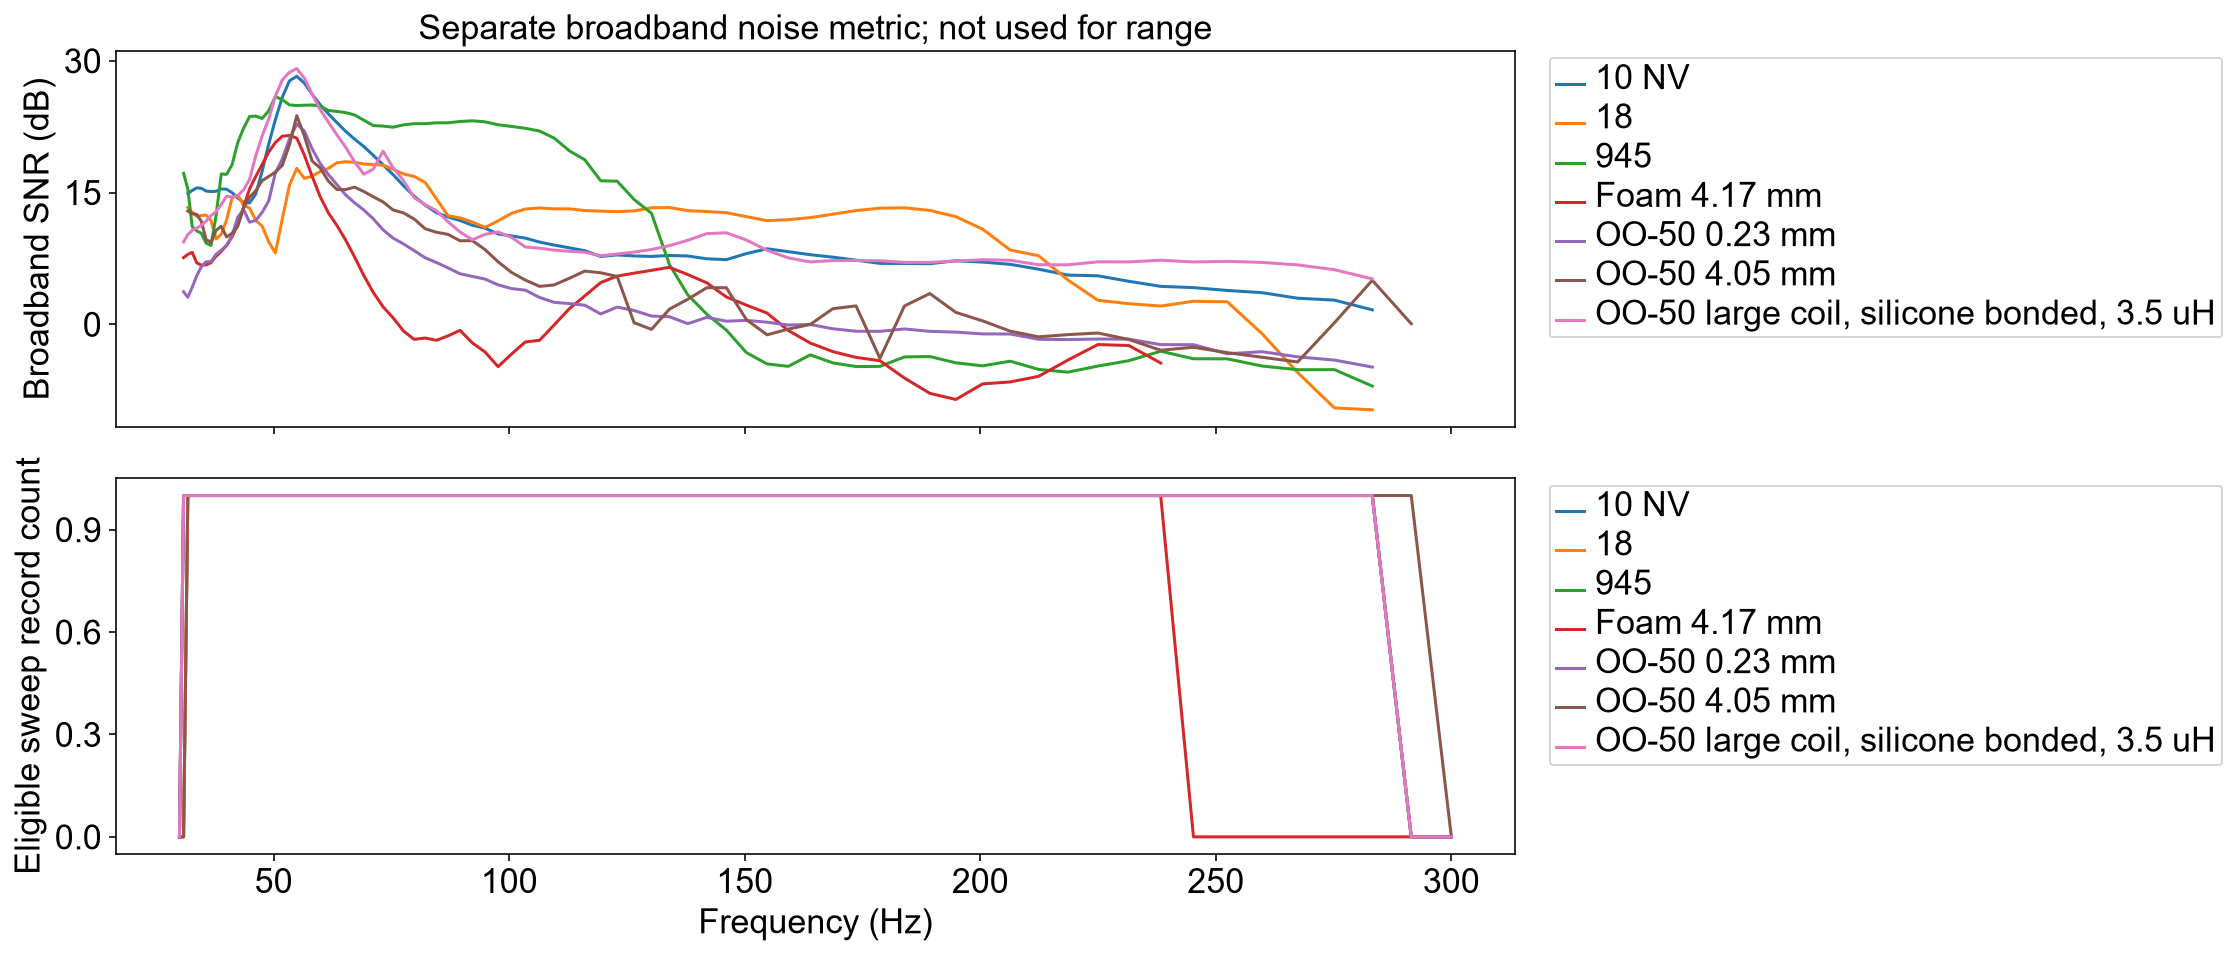

Exact output path: C:\Users\kangb3\Desktop\Research\Inductive Microphone\Figure2and3\results\2026-10-18_data11_harmonic_tracking_run001


In [11]:
display(RESULTS['intervals'])
display(RESULTS['summary'].groupby('material').agg(
    max_accepted_record_count=('n_snr', 'max'), supported_grid_points=('detectable', 'sum')))
show_figures('tracking_broadband_and_repeat_counts')
print('Exact output path:', OUTPUT_PATH)


## Interpretation limits

Fundamental amplitudes use offline swept-sine quadrature tracking with a centered Hann kernel. Background records use the same trajectory and matched estimator bandwidth. For the published selection, responsivity compares one selected IM recording with one independently acquired accelerometer recording at common frequencies.

Unresolved factors include clock accuracy, independent excitation verification, analog bandwidth and antialiasing, accelerometer frequency calibration, ADC voltage conversion, batch drift, mounting repeatability and tracking smoothing. The cause of some endpoint anomalies is unresolved. Insufficient accepted data remain unavailable; anomalous recordings are not substituted to improve SNR.


## Optional supplementary diagnostics

The core analysis ends here. Copy the exact `OUTPUT_PATH` printed above into `TRACKING_RUN` in [data11_frequency_range_supplement.ipynb](data11_frequency_range_supplement.ipynb) to inspect the strict comparison and accelerometer-reference plots, historical previews, reference-window audits or whole-sweep FFT comparisons. These are separate diagnostics; the supplement keeps the main run and its strict results unchanged.


## Optional: redraw existing results only

To change the axes without reanalyzing raw data, edit and run the `PLOT_YMAX` cell above, set `REDRAW_ONLY = True` below, and run this cell. It uses the complete tracking run selected by the current `OUTPUT_PATH`; if that path is absent from the kernel, it uses the explicitly named `2026-10-17_data11_harmonic_tracking_run004` run.

Figures are saved in a new directory and returned as `FIGURE_RESULTS` and `FIGURE_OUTPUT_PATH`. The original `RESULTS` and `OUTPUT_PATH` remain unchanged. The default `REDRAW_ONLY = False` prevents Run All from creating an additional figure run. This cell displays only the materials and coil-design main figures.


In [12]:
REDRAW_ONLY = False  # Set True, then run this cell to redraw the existing results.
if REDRAW_ONLY:
    from pathlib import Path
    import importlib
    import paper_figure_style as _paper_style
    import data11_harmonic_tracking as ht
    importlib.reload(_paper_style)
    importlib.reload(ht)
    REDRAW_PARENT = globals().get('OUTPUT_PATH') or (
        PROJECT / 'results' / '2026-10-17_data11_harmonic_tracking_run004')
    FIGURE_RESULTS = ht.export_tracking_figures(
        REDRAW_PARENT, NOTEBOOK_PATH, plot_ymax=PLOT_YMAX)
    FIGURE_OUTPUT_PATH = Path(FIGURE_RESULTS['output_path'])
    print('Exact figure output path:', FIGURE_OUTPUT_PATH)
    for _figure_path in FIGURE_RESULTS['figures']:
        if Path(_figure_path).stem in {
                'tracking_comparison_materials', 'tracking_comparison_coil_design'}:
            display(Image(filename=str(_figure_path)))
else:
    print('Redraw skipped. Set REDRAW_ONLY = True to export figures from existing results.')


Redraw skipped. Set REDRAW_ONLY = True to export figures from existing results.
